In [1]:
import numpy as np
import tensorflow as tf

from models.convnet_cifar import ConvNet_CIFAR
# from models.convnet_svhn import ConvNet_SVHN
from models.svhn_tree import SoftBinaryDecisionTree
from models.utils import brand_new_tfsession, draw_tree
from tensorflow.keras.callbacks import EarlyStopping, Callback, ReduceLROnPlateau, LearningRateScheduler
from tensorflow.keras.applications import ResNet50

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.model_selection import train_test_split
# 새 TF 세션 생성
sess = brand_new_tfsession()

c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages\tensorflow\python\framework\dtypes.py:526: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint8 = np.dtype([("qint8", np.int8, 1)])
c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages\tensorflow\python\framework\dtypes.py:527: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_quint8 = np.dtype([("quint8", np.uint8, 1)])
c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages\tensorflow\python\framework\dtypes.py:528: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint16 = np.dtype([("qint16", np.int16, 1)])
c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages

In [2]:
import os
import numpy as np
import h5py
from PIL import Image

# 이름 읽기
def _get_name(digitStructName, index, f):
    ref = digitStructName[index][0]
    name_data = f[ref][()]
    name = ''.join([chr(c) for c in name_data])
    return name

# 레이블 읽기
def _get_label(digitStructBbox, index, f):
    bbox = f[digitStructBbox[index][0]]
    label_item = bbox['label']

    if isinstance(label_item[0][0], h5py.Reference):
        if len(label_item) == 1:
            label_ref = label_item[0][0]
            label = int(f[label_ref][()][0][0])
        else:
            label_ref = label_item[0][0]
            label = int(f[label_ref][()][0][0])
    else:
        label = int(label_item[0][0])

    return label

# digitStruct.mat 읽기
def load_digitStruct_mat(path_to_mat):
    f = h5py.File(path_to_mat, 'r')
    digitStructName = f['digitStruct']['name']
    digitStructBbox = f['digitStruct']['bbox']

    filenames = []
    labels = []

    for i in range(len(digitStructName)):
        name = _get_name(digitStructName, i, f)
        label = _get_label(digitStructBbox, i, f)

        filenames.append(name)
        labels.append(label)

    return filenames, labels

# 이미지 불러오기
def load_images_from_folder(folder_path, filenames, labels, img_size=(32, 32)):
    images = []
    targets = []
    for filename, label in zip(filenames, labels):
        img_path = os.path.join(folder_path, filename)
        if os.path.exists(img_path):
            img = Image.open(img_path).convert('RGB')
            img = img.resize(img_size)
            img = np.array(img)
            images.append(img)
            targets.append(label)
    return np.array(images), np.array(targets)


In [3]:
def load_data(path):
    """ Load SVHN .mat file and transpose """
    data = loadmat(path)
    X = data['X'].transpose(3, 0, 1, 2)  # (32,32,3,N) → (N,32,32,3)
    y = data['y'].flatten()
    y[y == 10] = 0
    return X, y

x_train_full, y_train_full = load_data("./data/train_32x32.mat")
x_test, y_test = load_data("./data/test_32x32.mat")

In [4]:
# 2. Split into train / valid
x_train, x_valid, y_train, y_valid = train_test_split(
    x_train_full, y_train_full,
    test_size=0.3, random_state=42, stratify=y_train_full
)


# 3. 정확한 개수로 자르기
# x_train, y_train = x_train[:58600], y_train[:58600]
# x_valid, y_valid = x_valid[:14650], y_valid[:14650]
# x_test, y_test   = x_test[:26030], y_test[:26030]

In [5]:
#Printing the shape of training and testing dataset
print("Training_set:", x_train.shape, y_train.shape)
print("Validation_set:", x_valid.shape, y_valid.shape)
print("Test_set:", x_test.shape, y_test.shape)

Training_set: (51279, 32, 32, 3) (51279,)
Validation_set: (21978, 32, 32, 3) (21978,)
Test_set: (26032, 32, 32, 3) (26032,)


In [6]:
# 이미지 및 클래스 정보 추출
img_rows, img_cols, img_chans = x_train.shape[1:]
n_classes = np.unique(y_train).shape[0]
print(img_rows, img_cols, img_chans, n_classes)

32 32 3 10


In [7]:
# float32 변환
x_train = x_train.astype('float32')
x_valid = x_valid.astype('float32')
x_test  = x_test.astype('float32')

# mean/std는 train 기준으로만
mean = np.mean(x_train, axis=(0, 1, 2, 3))
std  = np.std(x_train, axis=(0, 1, 2, 3))

x_train = (x_train - mean) / (std + 1e-7)
x_valid = (x_valid - mean) / (std + 1e-7)
x_test  = (x_test - mean) / (std + 1e-7)


In [8]:
y_train[y_train == 10] = 0
y_valid[y_valid == 10] = 0
y_test[y_test == 10] = 0

# 3. one-hot 인코딩
y_train = tf.keras.utils.to_categorical(y_train, num_classes=10)
y_valid = tf.keras.utils.to_categorical(y_valid, num_classes=10)
y_test  = tf.keras.utils.to_categorical(y_test, num_classes=10)

In [9]:
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=10, min_lr=1e-05, verbose = 1)

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

In [10]:
# CNN 모델 정의 및 학습

svhn_nn = ConvNet_CIFAR(img_rows, img_cols, img_chans, n_classes, model_path = 'assets/svhn_teacher/svhn-model-version3.hdf5')
svhn_nn.maybe_train(data_train=(x_train, y_train),
               data_valid=(x_valid, y_valid),
               batch_size=64, callbacks = [early_stopping, reduce_lr], epochs=50)  # CIFAR-10은 조금 더 epoch 필요

Instructions for updating:
Colocations handled automatically by placer.
🔁 Trying to load full model from assets/svhn_teacher/svhn-model-version3.hdf5.
Instructions for updating:
Please use `rate` instead of `keep_prob`. Rate should be set to `rate = 1 - keep_prob`.


In [9]:
svhn_nn.evaluate(x_valid, y_valid)
svhn_nn.evaluate(x_test, y_test)

Evaluation Results:
 - Loss:      0.2428
 - Accuracy:  96.78%
 - Precision: 96.70%
 - Recall:    96.53%
 - F1-Score:  96.61%
Evaluation Results:
 - Loss:      0.2965
 - Accuracy:  95.90%
 - Precision: 95.57%
 - Recall:    95.55%
 - F1-Score:  95.56%


In [11]:
# Soft label 추출
y_train_soft = svhn_nn.predict(x_train, batch_size = 64)
print(y_train_soft.shape)

51279/51279 [==============================] - 21s 405us/sample
(51279, 10)


In [11]:
row_sums = np.sum(y_train_soft, axis=1)

print("🔥 soft label의 row 합 평균:", np.mean(row_sums))
print("📊 soft label의 row 합 최소값:", np.min(row_sums))
print("📊 soft label의 row 합 최대값:", np.max(row_sums))

🔥 soft label의 row 합 평균: 1.0
📊 soft label의 row 합 최소값: 0.9999996
📊 soft label의 row 합 최대값: 1.0000005


In [12]:
print(y_train_soft.shape, y_valid.shape)

(58605, 10) (14652, 10)


In [11]:
for layer in svhn_nn.model.layers:
    print(layer.name)

input_1
conv2d
activation
batch_normalization_v1
conv2d_1
activation_1
batch_normalization_v1_1
max_pooling2d
dropout
conv2d_2
activation_2
batch_normalization_v1_2
conv2d_3
activation_3
batch_normalization_v1_3
max_pooling2d_1
dropout_1
conv2d_4
activation_4
batch_normalization_v1_4
conv2d_5
activation_5
batch_normalization_v1_5
max_pooling2d_2
dropout_2
flatten
dense
dropout_3
dense_1


In [12]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D
from sklearn.decomposition import PCA
import numpy as np

# (1) Feature 추출 모델 정의 (conv2d_5 → max_pooling2d_2 → GAP)
intermediate_layer = svhn_nn.model.get_layer('max_pooling2d_2').output # max_pooling2d_2
gap_output = GlobalAveragePooling2D()(intermediate_layer)

feature_model = Model(
    inputs=svhn_nn.model.input,
    outputs=gap_output
)

# (2) Feature 추출
x_train_flat = feature_model.predict(x_train, batch_size=64)
x_valid_flat = feature_model.predict(x_valid, batch_size=64)
x_test_flat  = feature_model.predict(x_test,  batch_size=64)

print(x_train_flat.shape, x_valid_flat.shape, x_test_flat.shape)

(51279, 128) (21978, 128) (26032, 128)


In [ ]:
import optuna
from tensorflow.keras.callbacks import EarlyStopping
import glob
import os

# n_features = img_rows * img_cols * img_chans
n_features = x_train_flat.shape[1]
# batch_size = 4

# def sharpen_soft_labels(soft_labels, T):
#     softened = np.power(soft_labels, 1.0 / T)
#     softened = softened / np.sum(softened, axis=1, keepdims=True)
#     return softened

def objective(trial):
    sess = brand_new_tfsession()
    # 1. 튜닝할 하이퍼파라미터 설정
    tree_depth = trial.suggest_int("tree_depth", 4, 5)
    penalty_strength = trial.suggest_loguniform("penalty_strength", 0.01, 5.0)
    penalty_decay = trial.suggest_uniform("penalty_decay", 0.01, 0.5)
    ema_win_size = trial.suggest_int("ema_win_size", 500, 2000, step = 100)
    inv_temp = trial.suggest_uniform("inv_temp", 0.01, 1.0)
    learning_rate = trial.suggest_float("learning_rate", 5e-04, 1e-02, log = True)
    batch_size = trial.suggest_categorical("batch_size", [4, 8, 16])
    # tree_depth = trial.suggest_int("tree_depth", 4, 5)
    # penalty_strength = trial.suggest_loguniform("penalty_strength", 1e-2, 1e+1)
    # penalty_decay = trial.suggest_uniform("penalty_decay", 0.01, 0.5)
    # ema_win_size = trial.suggest_int("ema_win_size", 500, 1000, step = 100)
    # inv_temp = trial.suggest_uniform("inv_temp", 0.01, 0.1)
    # learning_rate = trial.suggest_float("learning_rate", 5e-04, 1e-02, log = True)
    # batch_size = trial.suggest_categorical("batch_size", [4, 8, 16])
    # T = trial.suggest_float("sharpen_T", 0.3, 1.0)  # 일반적으로 0.3 ~ 1.0
    # softened_labels = sharpen_soft_labels(y_train_soft, T=T)
    
    # 고유한 체크포인트 경로 생성 (Trial 번호 기반)
    checkpoint_dir = f"assets/svhn_optuna_trial/trial_{trial.number}/"
    checkpoint_path = os.path.join(checkpoint_dir, "tree-model")

    # 💡 기존 체크포인트가 있다면 삭제
    if os.path.isdir(checkpoint_dir):
        old_ckpts = glob.glob(os.path.join(checkpoint_dir, "tree-model*"))
        for file in old_ckpts:
            os.remove(file)
    else:
        os.makedirs(checkpoint_dir, exist_ok=True)


    # 2. 트리 모델 생성
    sess = brand_new_tfsession()  # 세션 초기화
    svhn_tree = SoftBinaryDecisionTree(
        tree_depth, n_features, n_classes,
        penalty_strength=penalty_strength,
        penalty_decay=penalty_decay,
        inv_temp=inv_temp,
        ema_win_size=ema_win_size,
        learning_rate=learning_rate
    )
    svhn_tree.build_model()

    # 3. 학습
    es = EarlyStopping(monitor='val_acc', patience=5, verbose=0)
    rl = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=5, min_lr=1e-06, verbose = 1)
    svhn_tree.initialize_variables(sess, x_train_flat, batch_size = batch_size)

    svhn_tree.maybe_train(
        sess = sess,
        data_train = (x_train_flat, y_train_soft),
        data_valid=(x_valid_flat, y_valid),
        batch_size=batch_size,
        epochs=30,  # 빠른 튜닝용 짧은 epoch (본 학습 때는 늘리면 됨)
        callbacks=[es, rl],
        model_path=checkpoint_path
    )

    # 4. 평가 지표 반환 (validation accuracy)
    score = svhn_tree.cifar_evaluate(x_valid_flat, y_valid, batch_size)
    tf.reset_default_graph()
    return score[1]  # val_acc

# 5. Optuna 튜닝 시작
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)  # 20번 실험 (조절 가능)

# 6. 최적 파라미터 확인
print("🎯 Best trial:")
print(study.best_trial)


In [ ]:
# 0.8137
params={'tree_depth': 5, 'penalty_strength': 0.5228122005287116, 'penalty_decay': 0.046895244703922395, 'ema_win_size': 1700, 'inv_temp': 0.6294154677543902, 'learning_rate': 0.0062835437112905455, 'batch_size': 4}

In [13]:
sess = brand_new_tfsession()

n_features = x_train_flat.shape[1]

svhn_tree = SoftBinaryDecisionTree(
    max_depth=5,
    n_features=n_features,
    n_classes=n_classes,
    penalty_strength= 0.5228122005287116,
    penalty_decay=0.046895244703922395,
    ema_win_size=1700,
    inv_temp=0.6294154677543902,
    learning_rate=0.0062835437112905455
)
svhn_tree.build_model()

Built tree has 32 leaves out of 63 nodes


In [14]:
# import glob
# import os
# for f in glob.glob('assets/svhn-distill-tree/tree-model*'):
#     os.remove(f)

import time
start_time = time.time()
print("🟢 학습 시작:", time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(start_time)))
svhn_tree.initialize_variables(sess, x_train_flat, batch_size = 4)

svhn_tree.maybe_train(
    sess=sess,
    data_train=(x_train_flat, y_train_soft),
    data_valid=(x_valid_flat, y_valid),
    batch_size=4,
    epochs=40,
    callbacks=[EarlyStopping(monitor='val_acc', patience=10)],
    distill=True,
    model_path="assets/svhn_student/svhn-distill-tree/tree-model"
)

# 4. 종료 시간 기록
end_time = time.time()
print("🔴 학습 종료:", time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(end_time)))

# 5. 총 소요 시간
elapsed = end_time - start_time
print(f"⏱️ 총 학습 시간: {elapsed:.2f}초 ({elapsed / 60:.2f}분)")

🟢 학습 시작: 2025-06-11 11:12:23
🔁 Loading trained model from assets/svhn_student/svhn-distill-tree/tree-model
Instructions for updating:
Use standard file APIs to check for files with this prefix.
INFO:tensorflow:Restoring parameters from assets/svhn_student/svhn-distill-tree/tree-model
🔴 학습 종료: 2025-06-11 11:12:23
⏱️ 총 학습 시간: 0.19초 (0.00분)


In [33]:
svhn_tree.evaluate(x=x_valid_flat, y=y_valid, batch_size=4)
svhn_tree.evaluate(x=x_test_flat, y=y_test, batch_size=4)

Evaluation Results:
 - Accuracy:  81.08%
 - Precision: 81.96%
 - Recall:    80.76%
 - F1-Score:  81.31%
Evaluation Results:
 - Accuracy:  84.36%
 - Precision: 84.80%
 - Recall:    84.23%
 - F1-Score:  84.46%


In [27]:
def draw_tree(sess, tree, img_rows, img_cols, img_chans,
              input_vector=None, input_img=None,
              show_correlation=False, savepath=''):

    import itertools
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.gridspec import GridSpec
    from matplotlib.patches import ConnectionPatch

    TITLE_FONT_SIZE = 20
    LOGIT_FONT_SIZE = 18

    def _add_arrow(ax_parent, ax_child, xyA, xyB, color='black'):
        con = ConnectionPatch(xyA=xyA, xyB=xyB, coordsA='data', coordsB='data',
                              axesA=ax_child, axesB=ax_parent, arrowstyle='<|-',
                              color=color)
        ax_child.add_artist(con)

    kernels = dict([(l.name.split('_')[-1],
                     np.squeeze(l.get_weights()[0]).reshape((img_rows, img_cols, img_chans)))
                    for l in tree.model.layers if 'dense' in l.name])
    biases = dict([(l.name.split('_')[-1], np.squeeze(l.get_weights()[1][0]))
                   for l in tree.model.layers if 'dense' in l.name])
    leaves = dict([(l.name.split('_')[-1], sess.run(l.output))
                   for l in tree.model.layers if 'pdist' in l.name])

    n_leaves = 2 ** tree.max_depth
    assert len(leaves) == n_leaves

    fig = plt.figure(figsize=(n_leaves, n_leaves // 2))
    gs = GridSpec(tree.max_depth + 1, n_leaves * 2, height_ratios=[1] * tree.max_depth + [0.5])

    gcx = [list(np.arange(1, 2 ** (i + 1), 2) * (2 ** (tree.max_depth + 1) // 2 ** (i + 1)))
           for i in range(tree.max_depth + 1)]
    gcx = list(itertools.chain.from_iterable(gcx))
    axes = {}
    path = ['0']

    imshow_args = {'origin': 'upper', 'interpolation': 'None', 'cmap': 'gray'}

    for pos, key in enumerate(sorted(kernels.keys(), key=lambda x: (len(x), x))):
        ax = plt.subplot(gs[len(key) - 1, gcx[pos] - 2:gcx[pos] + 2])
        axes[key] = ax
        kernel_image = kernels[key]
        if input_vector is not None and key in path:
            flat_kernel = kernels[key].flatten()
            logit = sess.run(tree.inv_temp)[0] * (
                np.dot(input_vector.flatten(), flat_kernel) + biases[key])
            path.append(key + ('1' if (logit) >= 0 else '0'))
            ax.text(img_cols // 2, img_rows + 2, '{:.2f}'.format(logit),
                    ha='center', va='center', fontsize=LOGIT_FONT_SIZE)
            if show_correlation:
                reshaped_input = input_vector.reshape(img_rows, img_cols, img_chans)
                kernel_image = reshaped_input * kernels[key]
        ax.imshow(kernel_image.squeeze(), **imshow_args)
        ax.axis('off')
        digits = set([np.argmax(leaves[k]) for k in leaves.keys() if k.startswith(key)])
        ax.set_title(','.join(str(d) for d in digits), fontsize=TITLE_FONT_SIZE)

    for pos, key in enumerate(sorted(leaves.keys(), key=lambda x: (len(x), x))):
        ax = plt.subplot(gs[len(key) - 1, gcx[len(kernels) + pos] - 1:gcx[len(kernels) + pos] + 1])
        axes[key] = ax
        leaf_image = np.ones((tree.n_classes, 1)) @ leaves[key]
        ax.imshow(leaf_image, **imshow_args)
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
        ax.set_title('{}'.format(np.argmax(leaves[key])), y=-.5, fontsize=TITLE_FONT_SIZE)

    for pos, key in enumerate(sorted(axes.keys(), key=lambda x: (len(x), x))):
        children_keys = [k for k in axes.keys() if len(k) == len(key) + 1 and k.startswith(key)]
        for child_key in children_keys:
            p_rows, p_cols = axes[key].get_images()[0].get_array().shape
            c_rows, c_cols = axes[child_key].get_images()[0].get_array().shape
            color = 'green' if (key in path and child_key in path) else 'red'
            _add_arrow(axes[key], axes[child_key],
                       (c_cols // 2, 1), (p_cols // 2, p_rows - 1), color)

    if input_img is not None:
        ax = plt.subplot(gs[0, 0:4])
        if input_img.ndim == 3 and input_img.shape[-1] == 3:
            ax.imshow(input_img, interpolation='bilinear')  # RGB 이미지일 때
        else:
            ax.imshow(input_img.squeeze(), cmap='gray', interpolation='bilinear')  # 흑백일 때
        ax.axis('off')
        ax.set_title('input', fontsize=TITLE_FONT_SIZE)
        _add_arrow(ax, axes['0'],
                   (1, img_rows // 2), (img_cols - 1, img_rows // 2), 'green')

    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, format = 'pdf', bbox_inches = 'tight')
        plt.close()
    else:
        plt.show()

In [15]:
label = 0  # airplane
np.random.seed(0)
sample_index = np.random.choice(np.where(np.argmax(y_test, axis=1) == label)[0])

# 트리에 입력된 feature vector (conv2d_23.mean)
input_vector = x_test_flat[sample_index]

# 원본 이미지 그대로
input_img = x_test[sample_index]  # shape: (32, 32, 3)

draw_tree(
    sess=sess,
    tree=svhn_tree,
    img_rows=8, img_cols=16, img_chans=1,
    input_vector=input_vector,
    input_img=input_img, 
    savepath = 'tree_visualization_before unlearning(svhn).pdf'
)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages\matplotlib\tight_layout.py:198: UserWarning: tight_layout cannot make axes width small enough to accommodate all axes decorations
  warnings.warn('tight_layout cannot make axes width small enough '


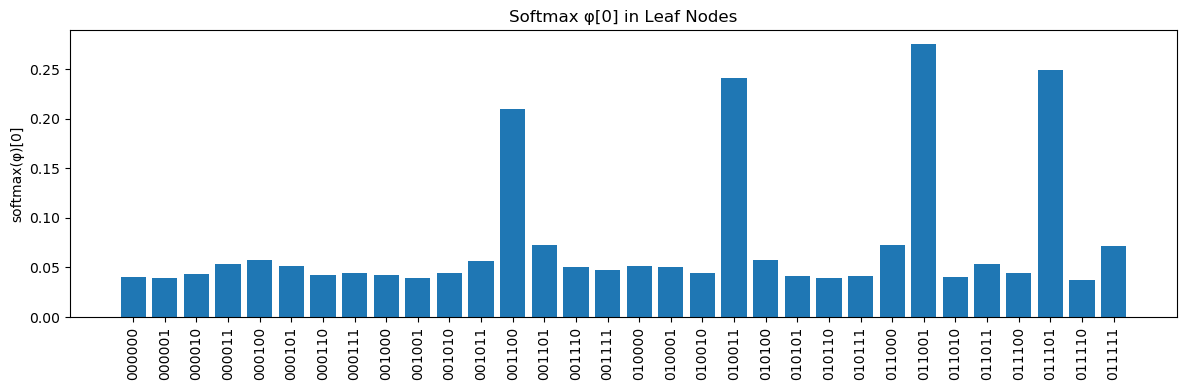

In [20]:
# 언러닝 전 리프노드 소프트맥스 분포
import matplotlib.pyplot as plt

def plot_leaf_node_phi_softmax(tree, sess, target_class=3):
    leaves = [n for n in tree.nodes if n.isLeaf]
    phi_values = []
    node_ids = []

    for leaf in leaves:
        raw_phi = sess.run(leaf.phi)[0]
        soft_phi = np.exp(raw_phi) / (np.sum(np.exp(raw_phi)) + 1e-8)
        phi_values.append(soft_phi[target_class])
        node_ids.append(leaf.id)

    plt.figure(figsize=(12, 4))
    plt.bar(range(len(phi_values)), phi_values, tick_label=node_ids)
    plt.xticks(rotation=90)
    plt.ylabel(f"softmax(φ)[{target_class}]")
    plt.title(f"Softmax φ[{target_class}] in Leaf Nodes")
    plt.tight_layout()
    plt.show()


plot_leaf_node_phi_softmax(tree=svhn_tree, sess=sess, target_class=0)


In [15]:
# 모든 리프노드의 클래스분포를 가져와서 그 중 target_class를 가장 강하게 예측하는 리프를 선택
# 유사 리프를 탐색 (유사 리프 중에서 타겟 클래스를 0.2 이상으로 예측하고 있음 distribution에서 제외 - 이미 target class에 대한 예측 성향이 강한데 굳이 distribution해서 확률을 얹어 높이고 싶진 않음)
# alpha값을 조절하여 alpha 만큼 유사 리프들에 분산 후 정규화 -> 확률값 합은 1로 만들기
# 타겟 리프에 도달하는 경로에 있는 내부 노드들의 weight 약화, 약화 비율은 target_class의 확률에 비례

def unlearn_target_class(tree, sess, target_class=3, top_k=3, alpha=0.3, pruning_rate=0.7, save_path=None):
    import numpy as np
    from sklearn.metrics.pairwise import cosine_similarity
    import os

    leaves = [n for n in tree.nodes if n.isLeaf]
    
    # ⛳ 업데이트 가능한 φ 값을 가져오기
    leaf_phis = {leaf: sess.run(leaf.phi) for leaf in leaves}
    
    # 🎯 타겟 클래스를 가장 강하게 예측하는 리프 찾기
    target_leaves = [leaf for leaf, phi in leaf_phis.items()
                     if np.argmax(phi) == target_class]

    # 🔍 각 타겟 리프에 대해 유사한 리프 탐색
    similar_map = {}
    for t_leaf in target_leaves:
        t_phi = leaf_phis[t_leaf].reshape(1, -1)
        sims = []
        for other_leaf in leaves:
            if other_leaf == t_leaf:
                continue
            o_phi = leaf_phis[other_leaf].reshape(1, -1)
            # 너무 강하게 target_class인 경우 분산 제외
            if np.argmax(o_phi) == target_class or o_phi[0, target_class] > 0.2:
                continue
            sim = cosine_similarity(t_phi, o_phi)[0, 0]
            sims.append((other_leaf, sim))
        similar_map[t_leaf] = sorted(sims, key=lambda x: -x[1])[:top_k]

    # 🌿 타겟 리프 φ 수정 및 유사 리프에 soft 분산
    for t_leaf in target_leaves:
        t_phi_val = leaf_phis[t_leaf]
        phi_tc = t_phi_val[0, target_class]
        redistributed_value = phi_tc * alpha
        residual_phi = np.copy(t_phi_val)
        residual_phi[0, target_class] = phi_tc * (1 - alpha)

        total_sim = sum([s for _, s in similar_map[t_leaf]]) + 1e-8

        for other_leaf, sim in similar_map[t_leaf]:
            ratio = sim / total_sim
            addition = redistributed_value * ratio

            updated_phi = np.copy(leaf_phis[other_leaf])
            updated_phi[0, target_class] += addition
            updated_phi /= np.sum(updated_phi) + 1e-8

            phi_var = [v for v in tf.global_variables()
                       if v.name.startswith('phi_' + other_leaf.id)][0]
            sess.run(tf.assign(phi_var, updated_phi.astype(np.float32)))
            leaf_phis[other_leaf] = updated_phi  # 🔄 최신화

        # 자기 자신도 업데이트
        residual_phi /= np.sum(residual_phi) + 1e-8
        phi_var = [v for v in tf.global_variables()
                   if v.name.startswith('phi_' + t_leaf.id)][0]
        sess.run(tf.assign(phi_var, residual_phi.astype(np.float32)))
        leaf_phis[t_leaf] = residual_phi  # 🔄 최신화

        # 🌳 Soft pruning: 경로 노드 weight 약화
        def find_path_to_leaf(root, target):
            path = []
            def dfs(node, current_path):
                if node == target:
                    path.extend(current_path)
                    return True
                if node.isLeaf:
                    return False
                return dfs(node.leftChild, current_path + [node]) or dfs(node.rightChild, current_path + [node])
            dfs(tree.root, [])
            return path

        importance = float(t_phi_val[0, target_class])
        pruning_scale = 1.0 - importance * pruning_rate
        path_nodes = find_path_to_leaf(tree.root, t_leaf)

        for node in path_nodes:
            dense_vars = [v for v in tf.global_variables()
                          if v.name.startswith('dense_' + node.id)]
            for var in dense_vars:
                current_val = sess.run(var)
                weakened_val = current_val * pruning_scale
                sess.run(tf.assign(var, weakened_val))

    # 🧹 φ[target_class]가 여전히 높은 리프 soft suppression (강제 제거)
    for leaf in leaves:
        phi_val = sess.run(leaf.phi)  # 갱신된 값으로 다시 확인
        if phi_val[0, target_class] > 0.05:
            adjusted_phi = np.copy(phi_val)
            adjusted_phi[0, target_class] = 0.0  # 🔒 완전 제거
            adjusted_phi /= np.sum(adjusted_phi) + 1e-8
            phi_var = [v for v in tf.global_variables()
                       if v.name.startswith('phi_' + leaf.id)][0]
            sess.run(tf.assign(phi_var, adjusted_phi.astype(np.float32)))

    print("✅ Soft redistribution unlearning applied to class", target_class)

    # 💾 저장
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        tree.save_variables(sess, save_path)
        print(f"📁 Unlearned model saved to: {save_path}")


In [16]:
target_class = 0

# 예시 경로 지정
save_path = "result/svhn/unlearned"

# 언러닝 및 저장 실행
unlearn_target_class(svhn_tree, sess, target_class=0, top_k=2, alpha=0.5, pruning_rate=0.7, save_path=save_path)

# 언러닝 후 모델 평가
# 테스트 데이터셋으로 평가
from sklearn.metrics import precision_score, recall_score, f1_score

feed_dict = {svhn_tree.input_layer: x_test_flat}
predictions = sess.run(svhn_tree.output_layer, feed_dict=feed_dict)
pred_classes = np.argmax(predictions, axis=1)
true_classes = np.argmax(y_test, axis=1)

accuracy = np.mean(pred_classes == true_classes)
print(f"\nTest accuracy after unlearning: {accuracy:.4f}")

# 전체 성능 지표
print("\n=== Overall Performance ===")
print(f"Precision (macro): {precision_score(true_classes, pred_classes, average='macro'):.4f}")
print(f"Recall    (macro): {recall_score(true_classes, pred_classes, average='macro'):.4f}")
print(f"F1-score  (macro): {f1_score(true_classes, pred_classes, average='macro'):.4f}")
print("\n=== Full Classification Report ===")

# 🎯 타겟 클래스에 대한 성능
target_class = 0
target_mask = np.argmax(y_test, axis=1) == target_class
if np.sum(target_mask) > 0:
    print("\n=== Target Class Performance ===")
    target_acc = np.mean(pred_classes[target_mask] == true_classes[target_mask])
    print(f"Target class accuracy: {target_acc:.4f}")
    print(f"Target class precision: {precision_score(true_classes[target_mask], pred_classes[target_mask], average='macro', zero_division=0):.4f}")
    print(f"Target class recall:    {recall_score(true_classes[target_mask], pred_classes[target_mask], average='macro', zero_division=0):.4f}")
    print(f"Target class F1-score:  {f1_score(true_classes[target_mask], pred_classes[target_mask], average='macro', zero_division=0):.4f}")

# ✅ 비타겟 클래스 성능
non_target_mask = np.argmax(y_test, axis=1) != target_class
if np.sum(non_target_mask) > 0:
    print("\n=== Non-Target Class Performance ===")
    non_target_acc = np.mean(pred_classes[non_target_mask] == true_classes[non_target_mask])
    print(f"Non-target class accuracy: {non_target_acc:.4f}")
    print(f"Non-target precision: {precision_score(true_classes[non_target_mask], pred_classes[non_target_mask], average='macro', zero_division=0):.4f}")
    print(f"Non-target recall:    {recall_score(true_classes[non_target_mask], pred_classes[non_target_mask], average='macro', zero_division=0):.4f}")
    print(f"Non-target F1-score:  {f1_score(true_classes[non_target_mask], pred_classes[non_target_mask], average='macro', zero_division=0):.4f}")

✅ Soft redistribution unlearning applied to class 0
📁 Unlearned model saved to: result/svhn/unlearned

Test accuracy after unlearning: 0.7690

=== Overall Performance ===
Precision (macro): 0.6856
Recall    (macro): 0.7498
F1-score  (macro): 0.7096

=== Full Classification Report ===

=== Target Class Performance ===
Target class accuracy: 0.0000
Target class precision: 0.0000
Target class recall:    0.0000
Target class F1-score:  0.0000

=== Non-Target Class Performance ===
Non-target class accuracy: 0.8242
Non-target precision: 0.8208
Non-target recall:    0.8331
Non-target F1-score:  0.8243


c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages\sklearn\metrics\_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [32]:
digit = 0
target_indices = np.where(np.argmax(y_test, axis=1) == digit)[0]

for i in range(4):
    raw_img = x_test[target_indices[i]]               # (32, 32, 3)
    input_vec = x_test_flat[target_indices[i]]        # (128,)

    print(f"📷 Sample #{i+1} (class {digit})")
    draw_tree(
        sess=sess,
        tree=svhn_tree,
        img_rows=8, img_cols=16, img_chans=1,
        input_vector=input_vec,
        input_img=raw_img,
        show_correlation=True,
        savepath = 'tree_visualization_after unlearning(svhn).pdf'
    )

📷 Sample #1 (class 0)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages\matplotlib\tight_layout.py:198: UserWarning: tight_layout cannot make axes width small enough to accommodate all axes decorations
  warnings.warn('tight_layout cannot make axes width small enough '


📷 Sample #2 (class 0)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


📷 Sample #3 (class 0)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


📷 Sample #4 (class 0)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


📷 Sample #1 (class 1)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


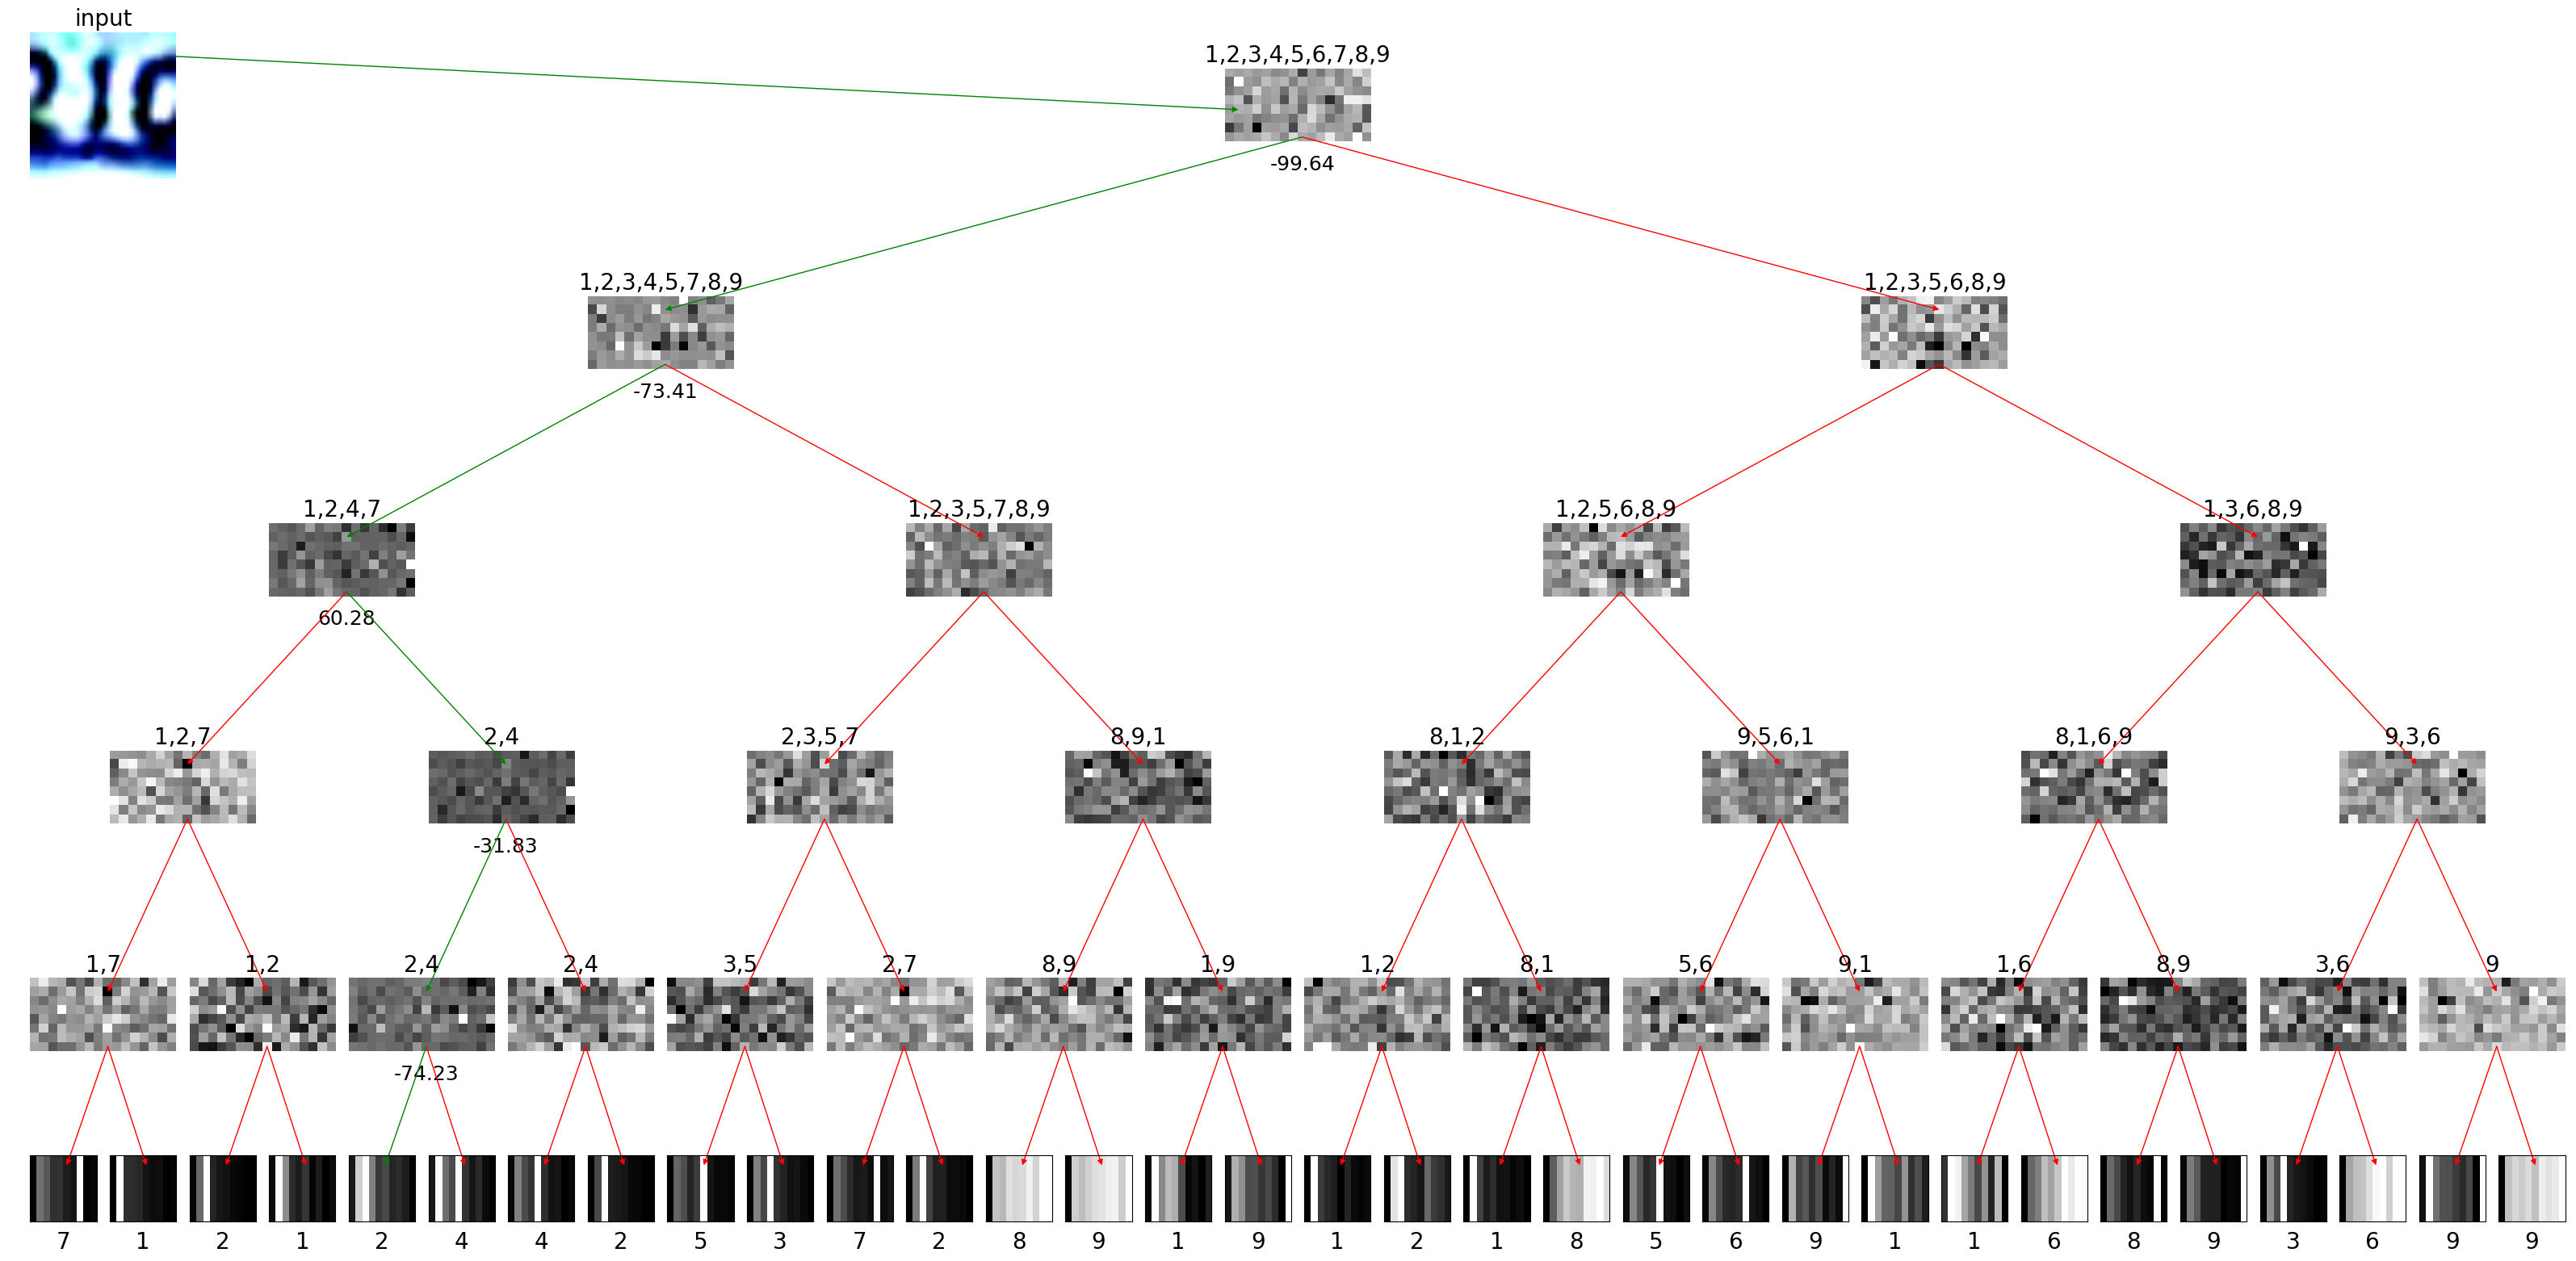

📷 Sample #2 (class 1)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


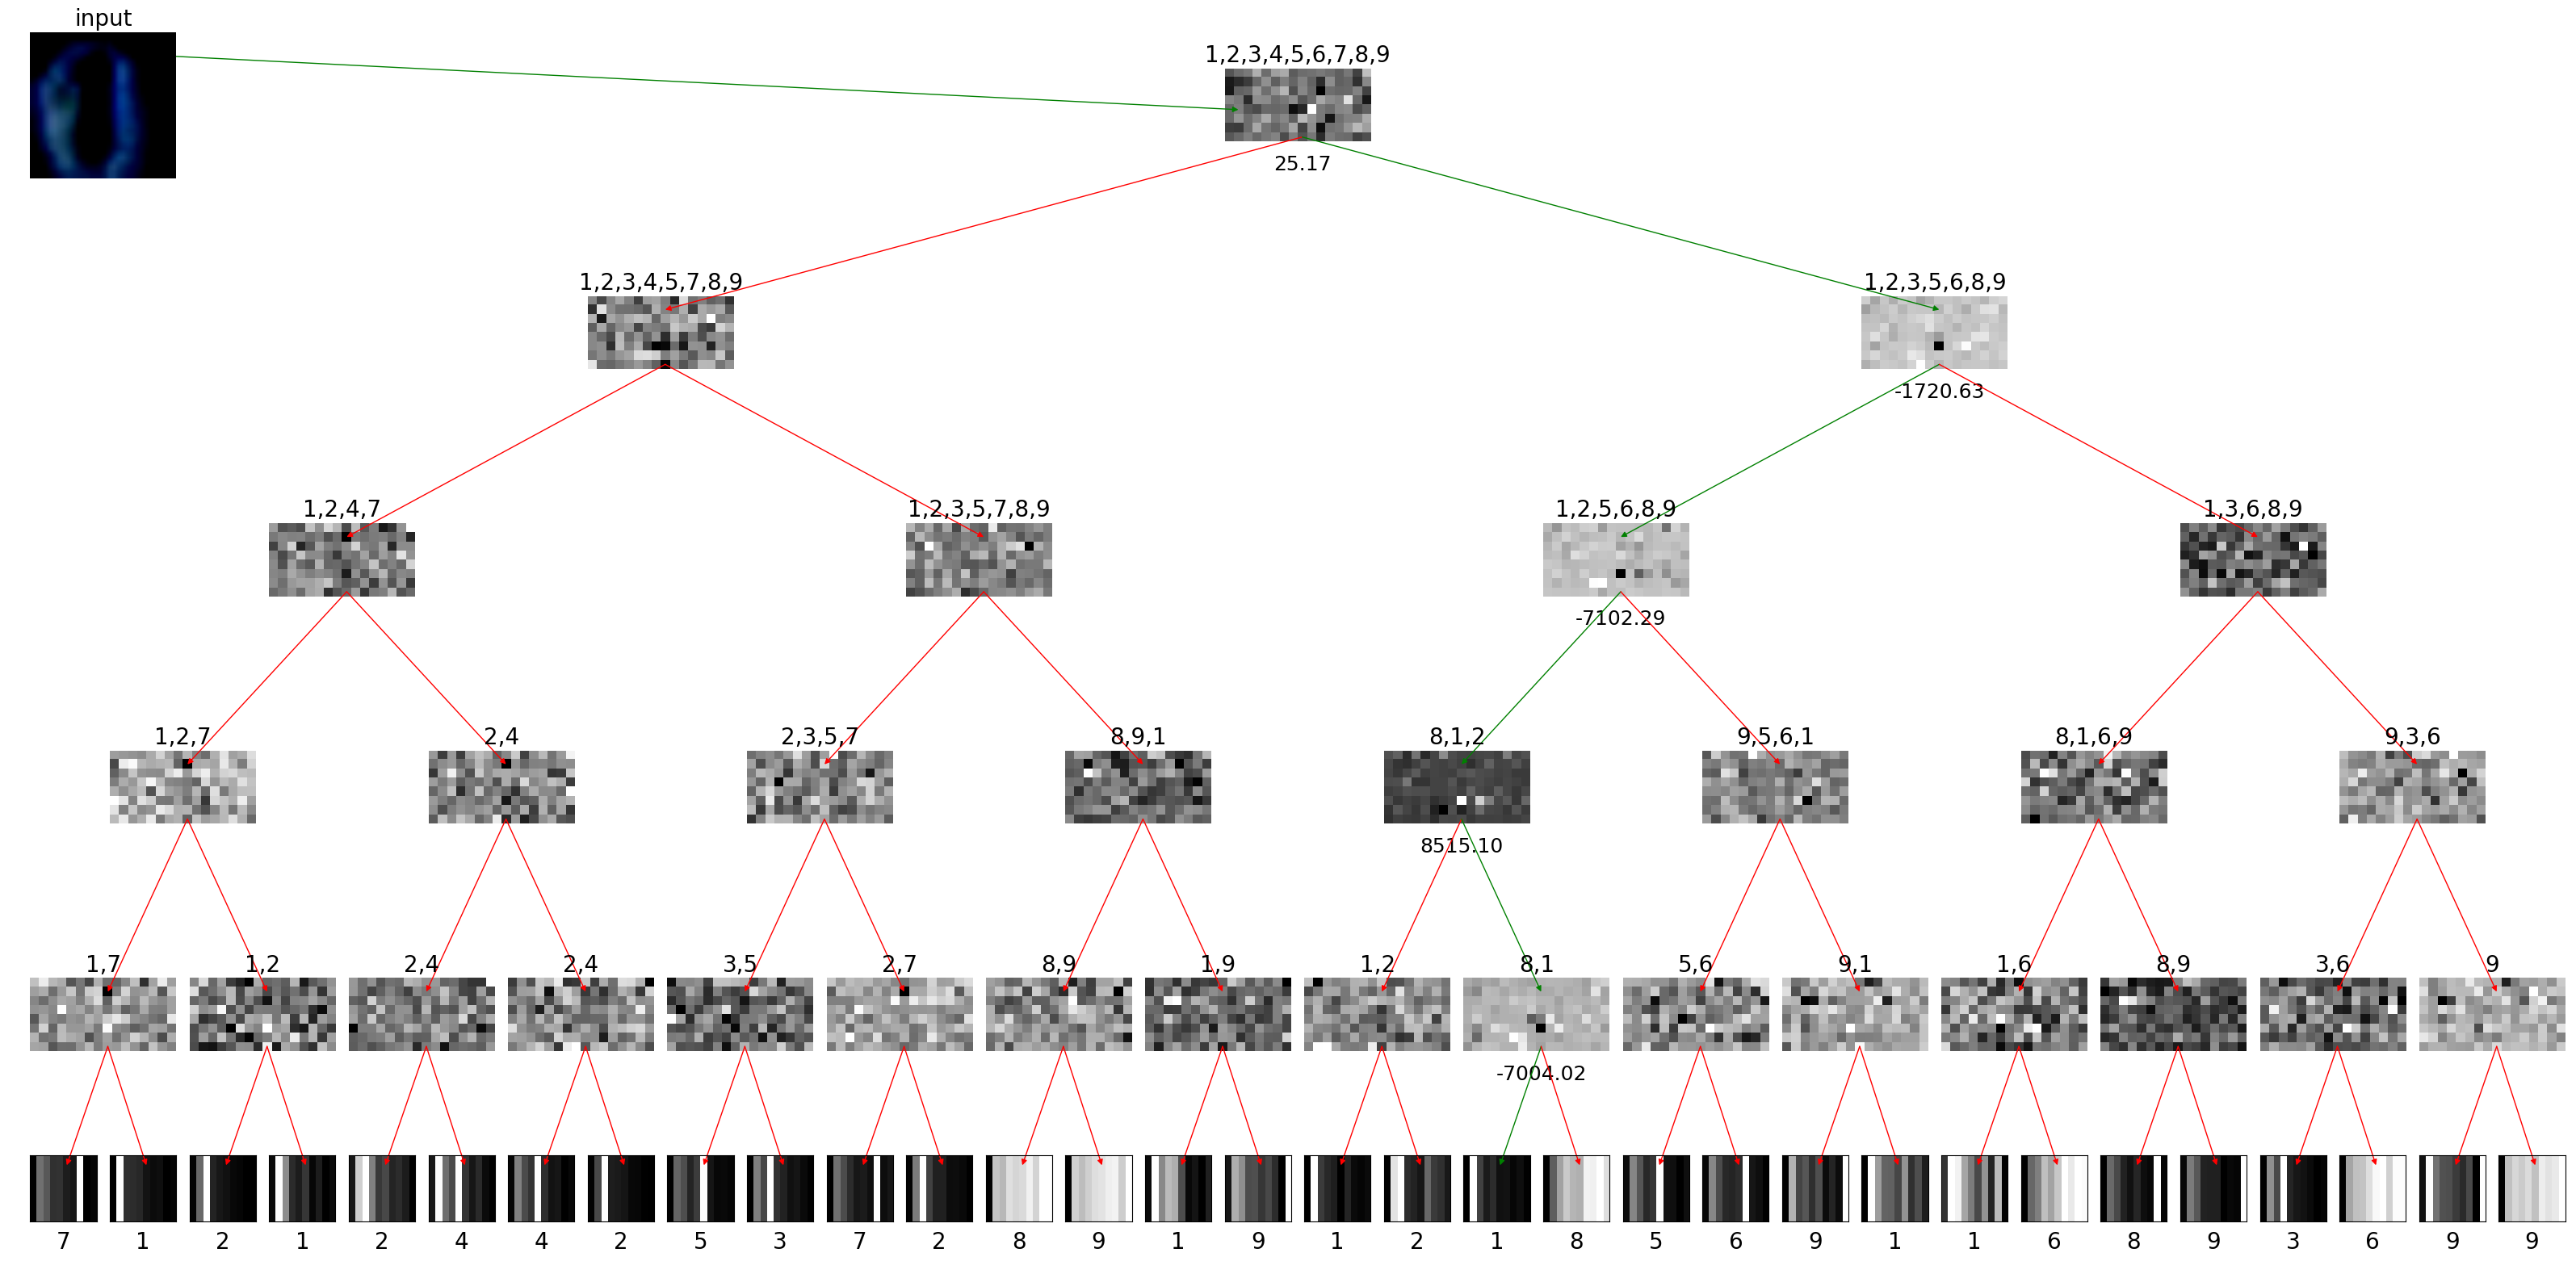

📷 Sample #3 (class 1)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


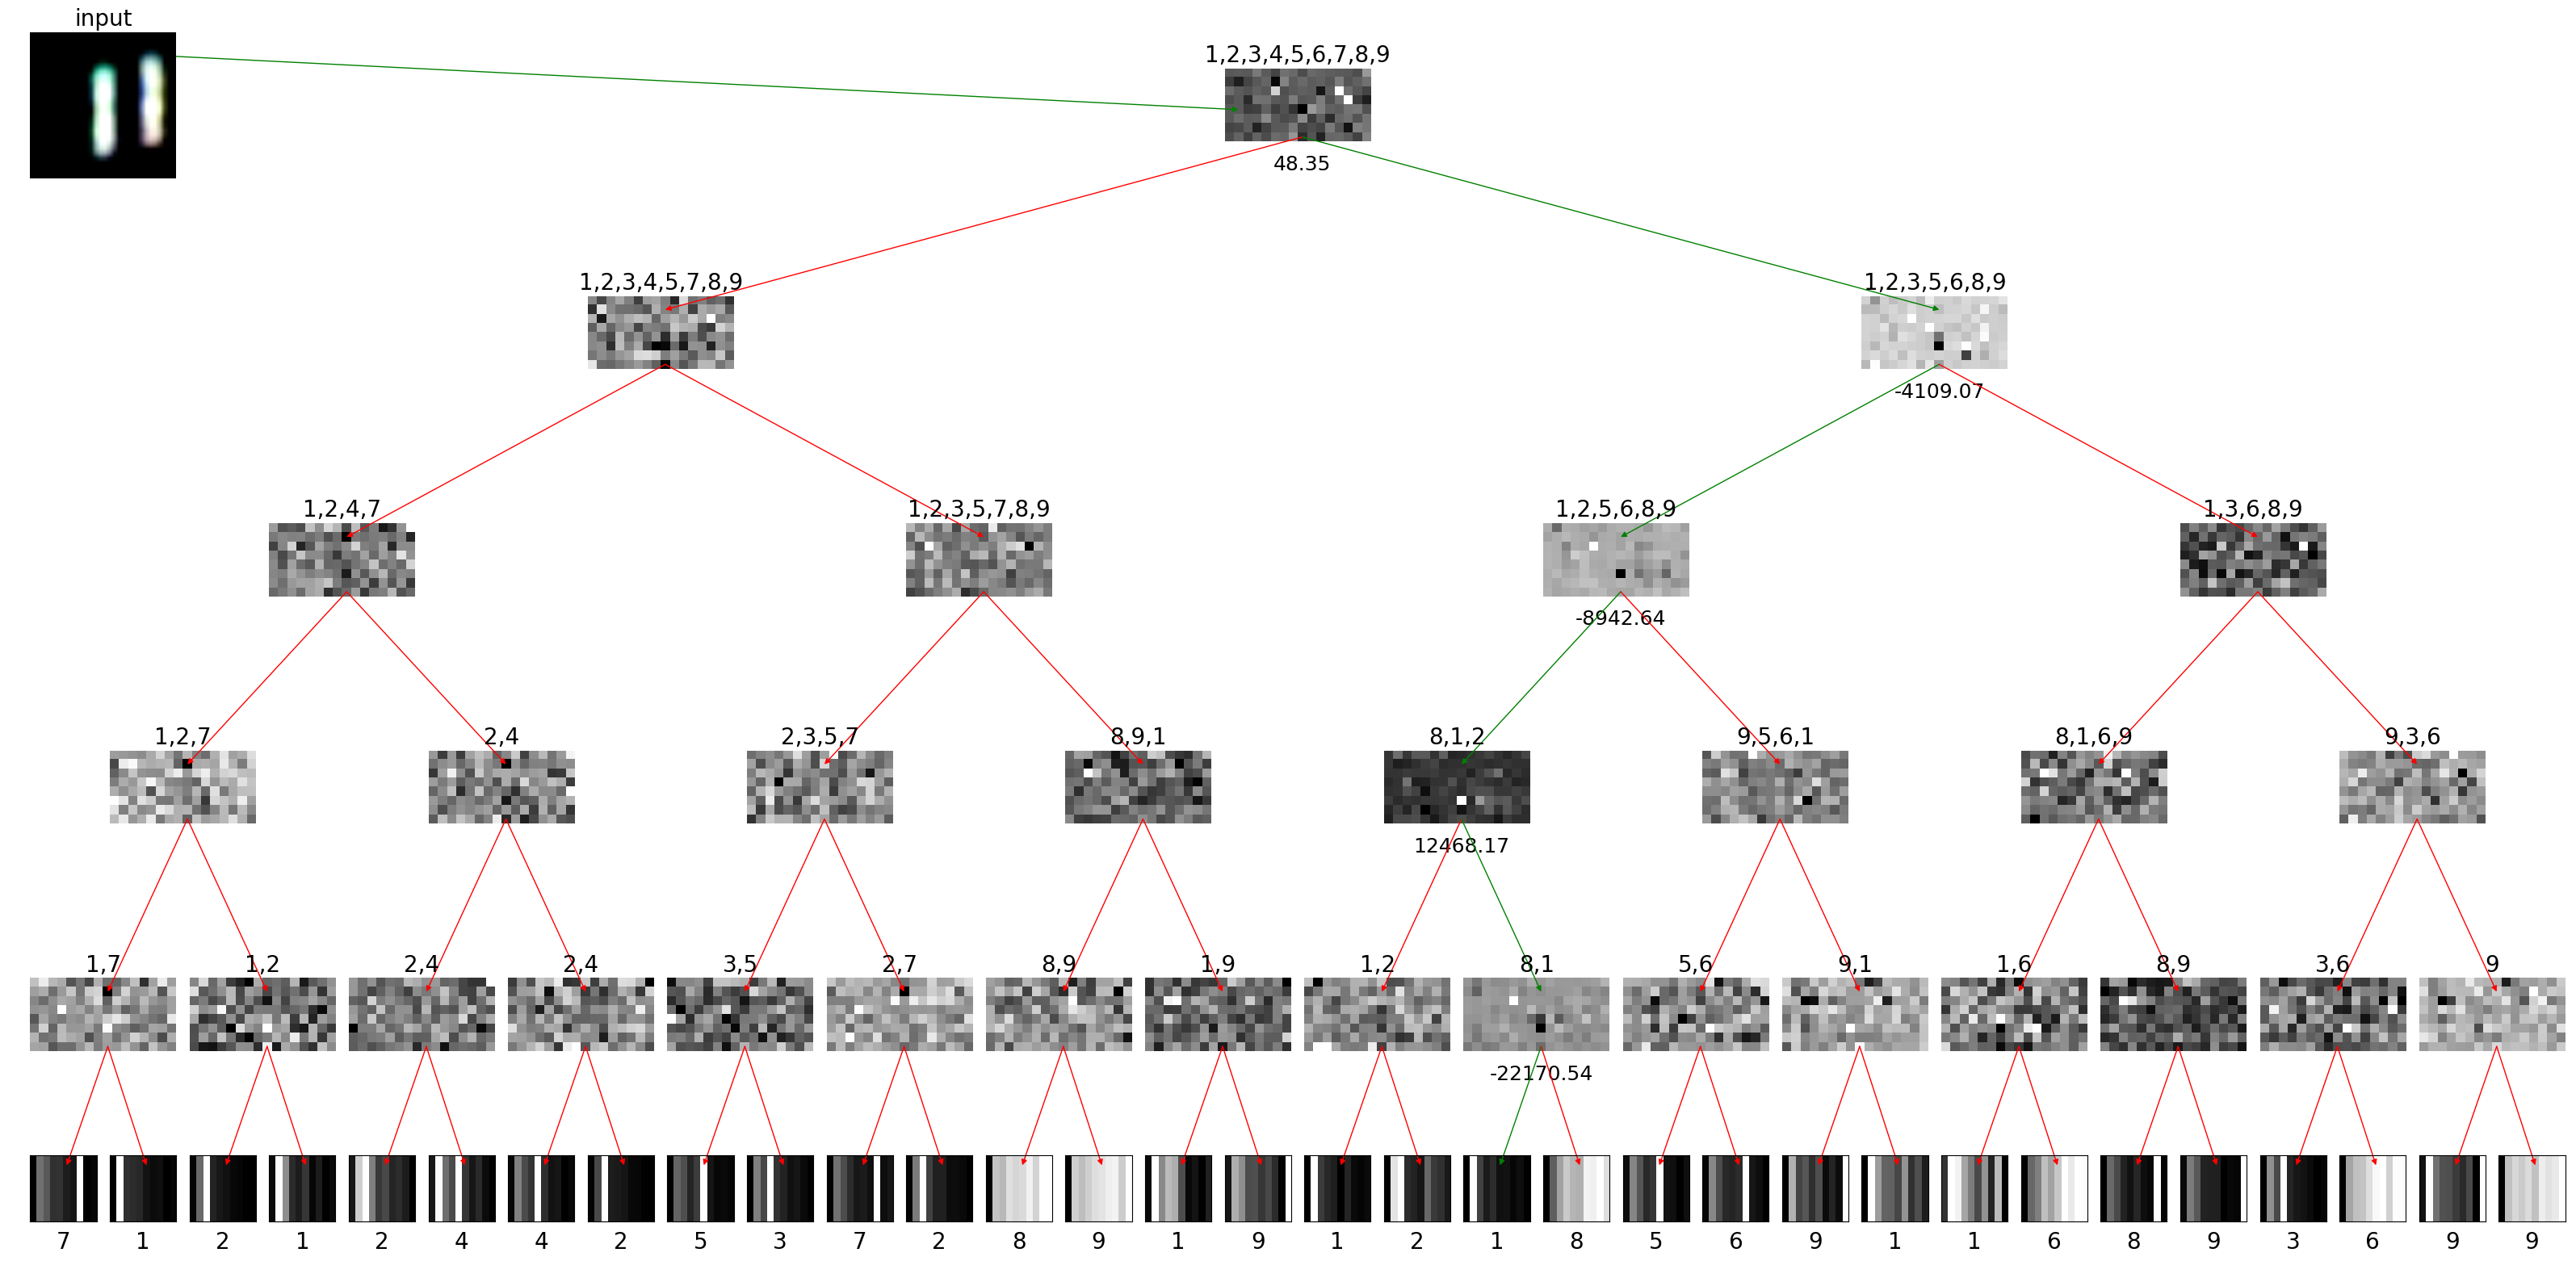

📷 Sample #4 (class 1)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


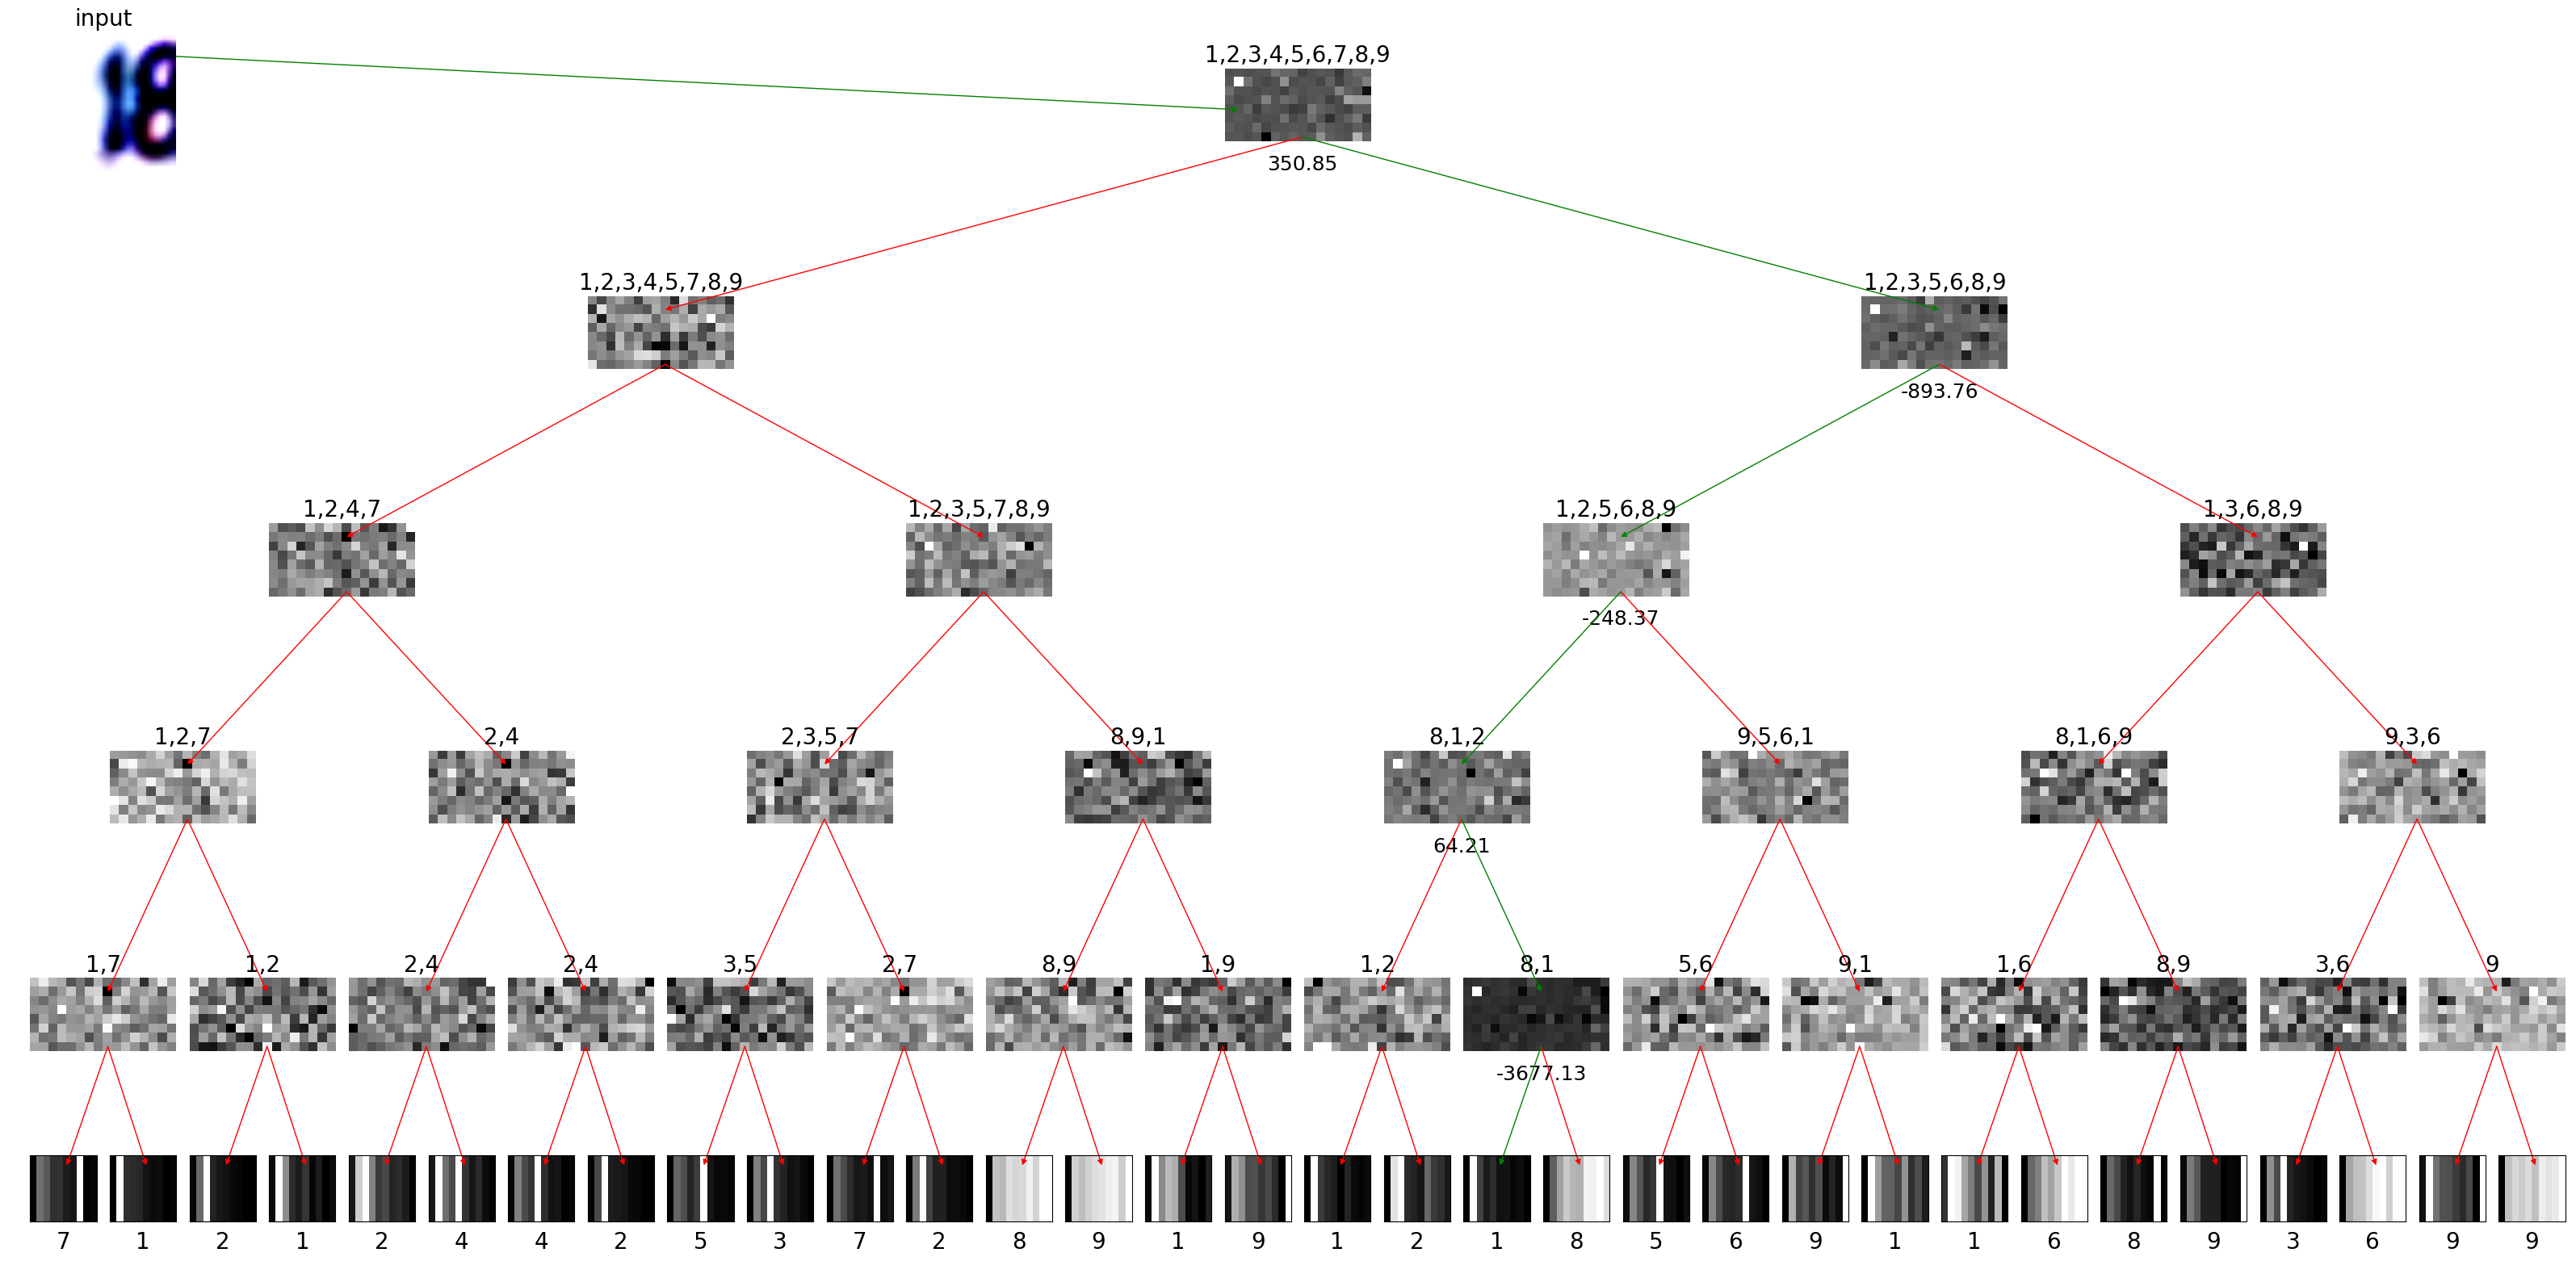

📷 Sample #5 (class 1)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


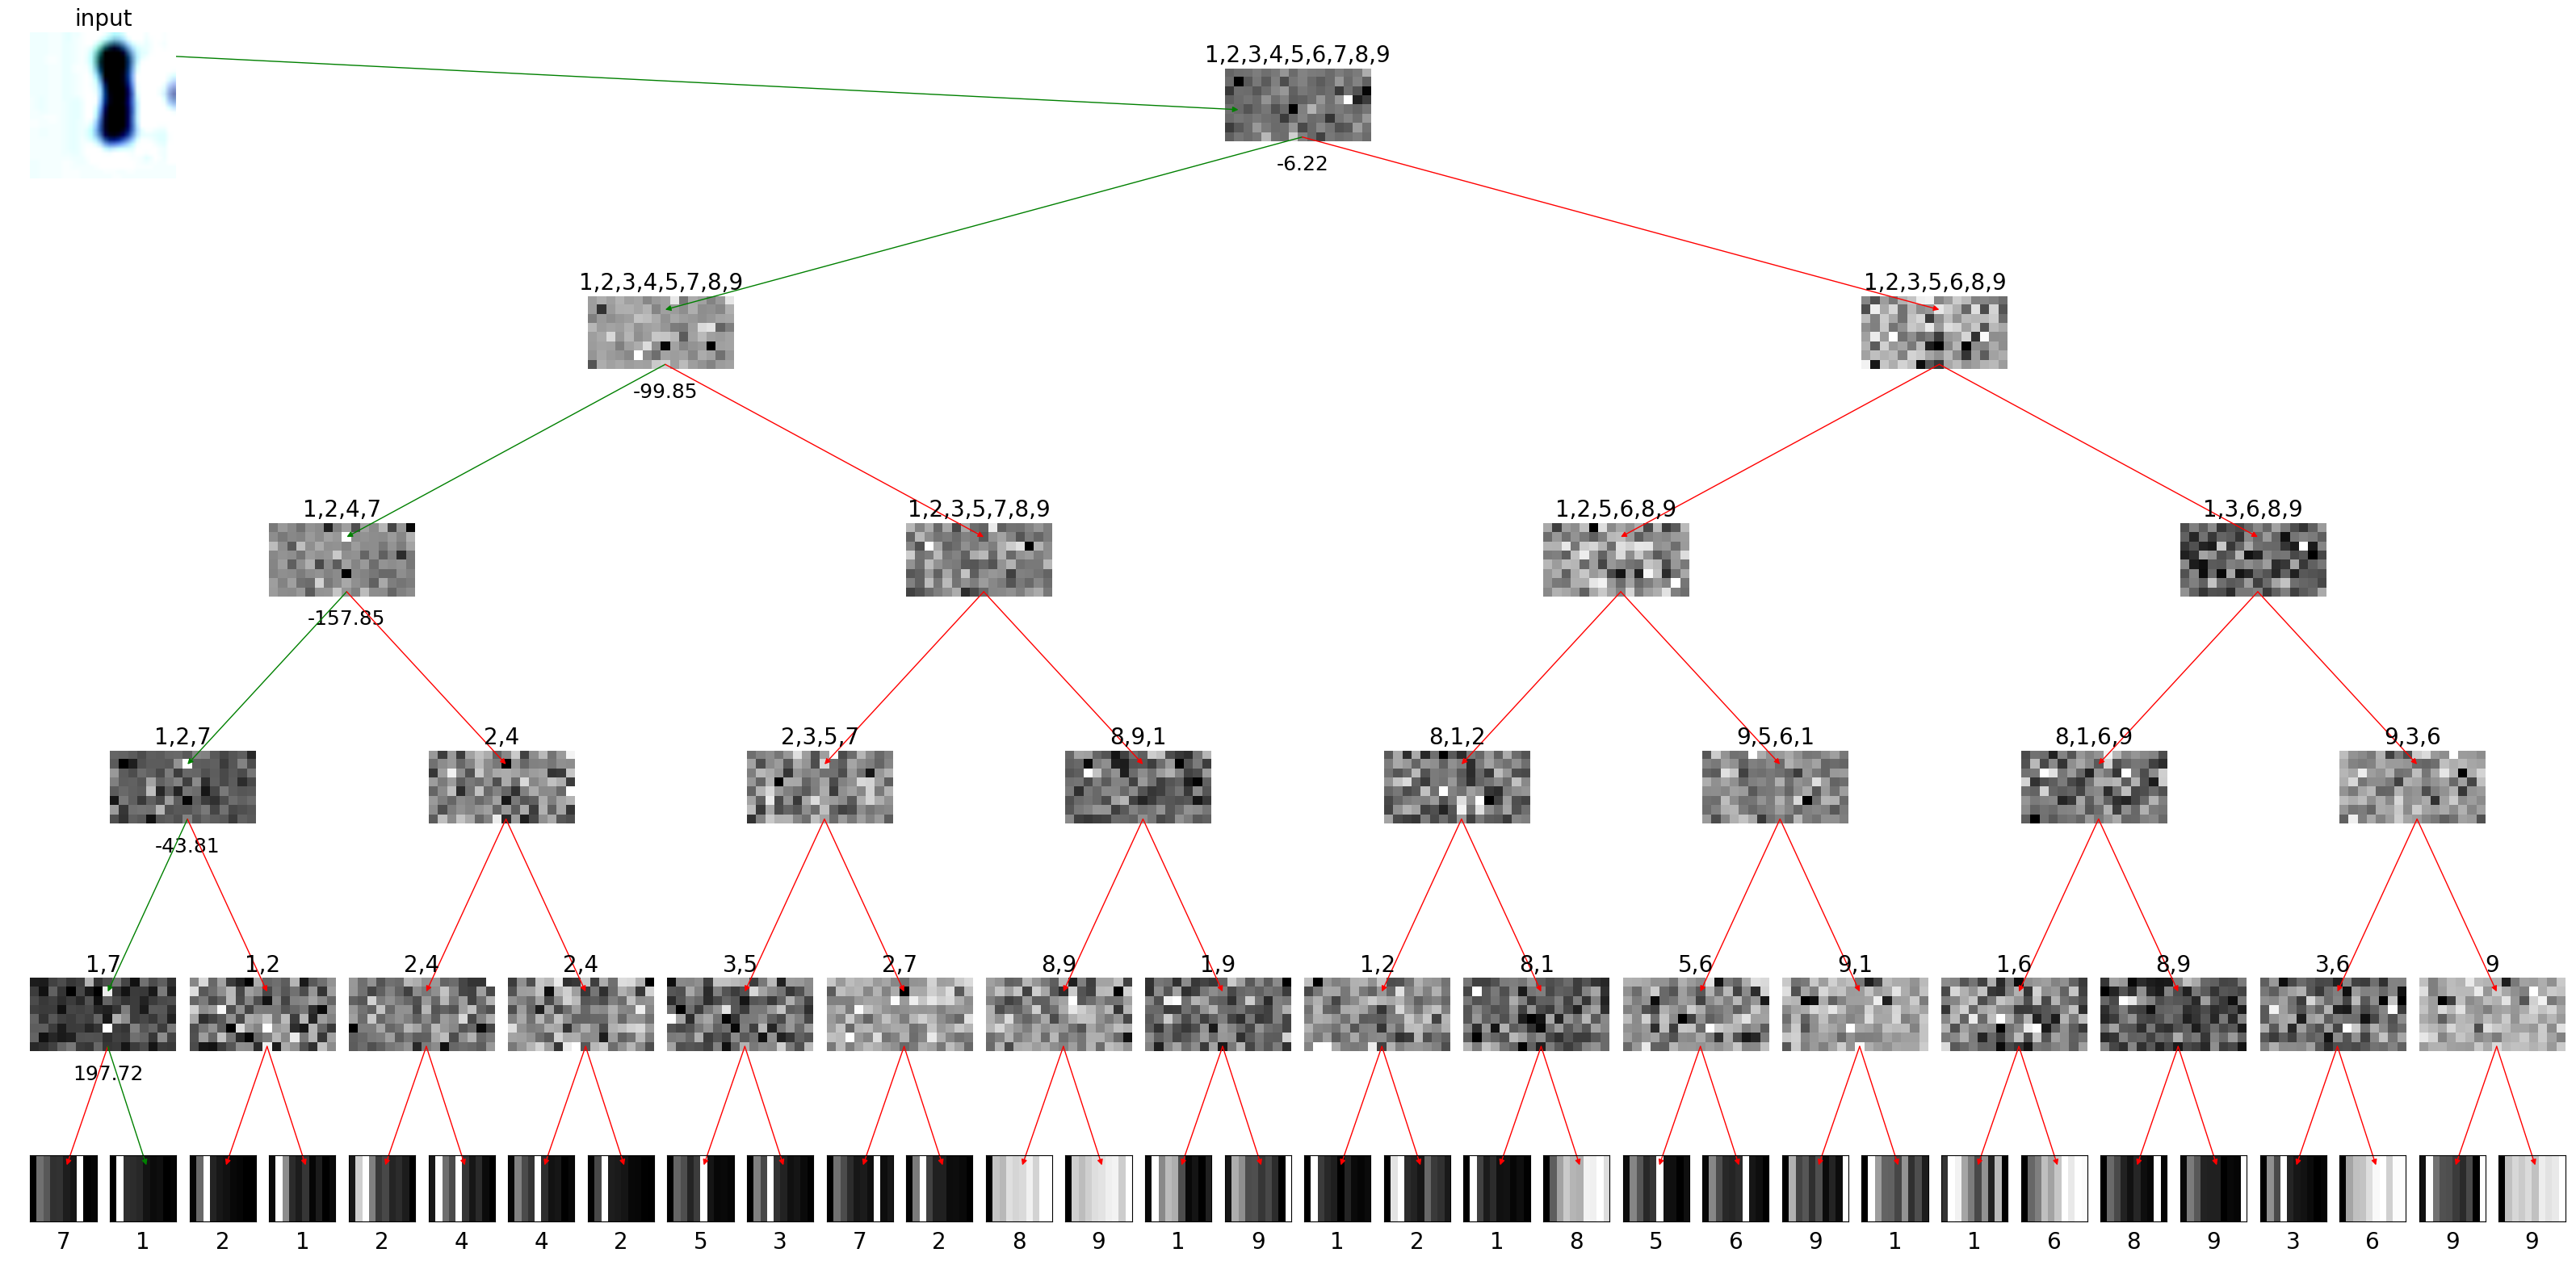

In [56]:
digit = 1
target_indices = np.where(np.argmax(y_test, axis=1) == digit)[0]

for i in range(5):
    raw_img = x_test[target_indices[i]]               # (32, 32, 3)
    input_vec = x_test_flat[target_indices[i]]        # (128,)

    print(f"📷 Sample #{i+1} (class {digit})")
    draw_tree(
        sess=sess,
        tree=svhn_tree,
        img_rows=8, img_cols=16, img_chans=1,
        input_vector=input_vec,
        input_img=raw_img,
        show_correlation=True
    )

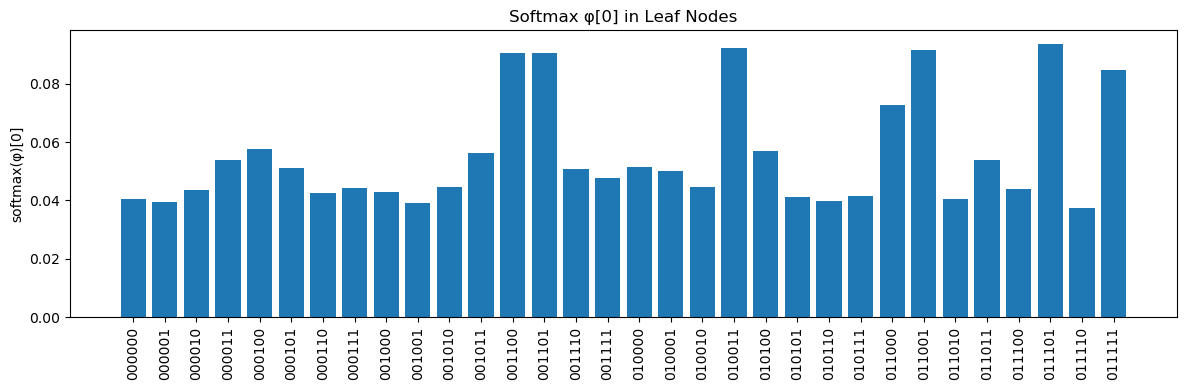

In [33]:
import matplotlib.pyplot as plt

def plot_leaf_node_phi_softmax(tree, sess, target_class=3):
    leaves = [n for n in tree.nodes if n.isLeaf]
    phi_values = []
    node_ids = []

    for leaf in leaves:
        raw_phi = sess.run(leaf.phi)[0]
        soft_phi = np.exp(raw_phi) / (np.sum(np.exp(raw_phi)) + 1e-8)
        phi_values.append(soft_phi[target_class])
        node_ids.append(leaf.id)

    plt.figure(figsize=(12, 4))
    plt.bar(range(len(phi_values)), phi_values, tick_label=node_ids)
    plt.xticks(rotation=90)
    plt.ylabel(f"softmax(φ)[{target_class}]")
    plt.title(f"Softmax φ[{target_class}] in Leaf Nodes")
    plt.tight_layout()
    plt.show()


plot_leaf_node_phi_softmax(tree=svhn_tree, sess=sess, target_class=0)


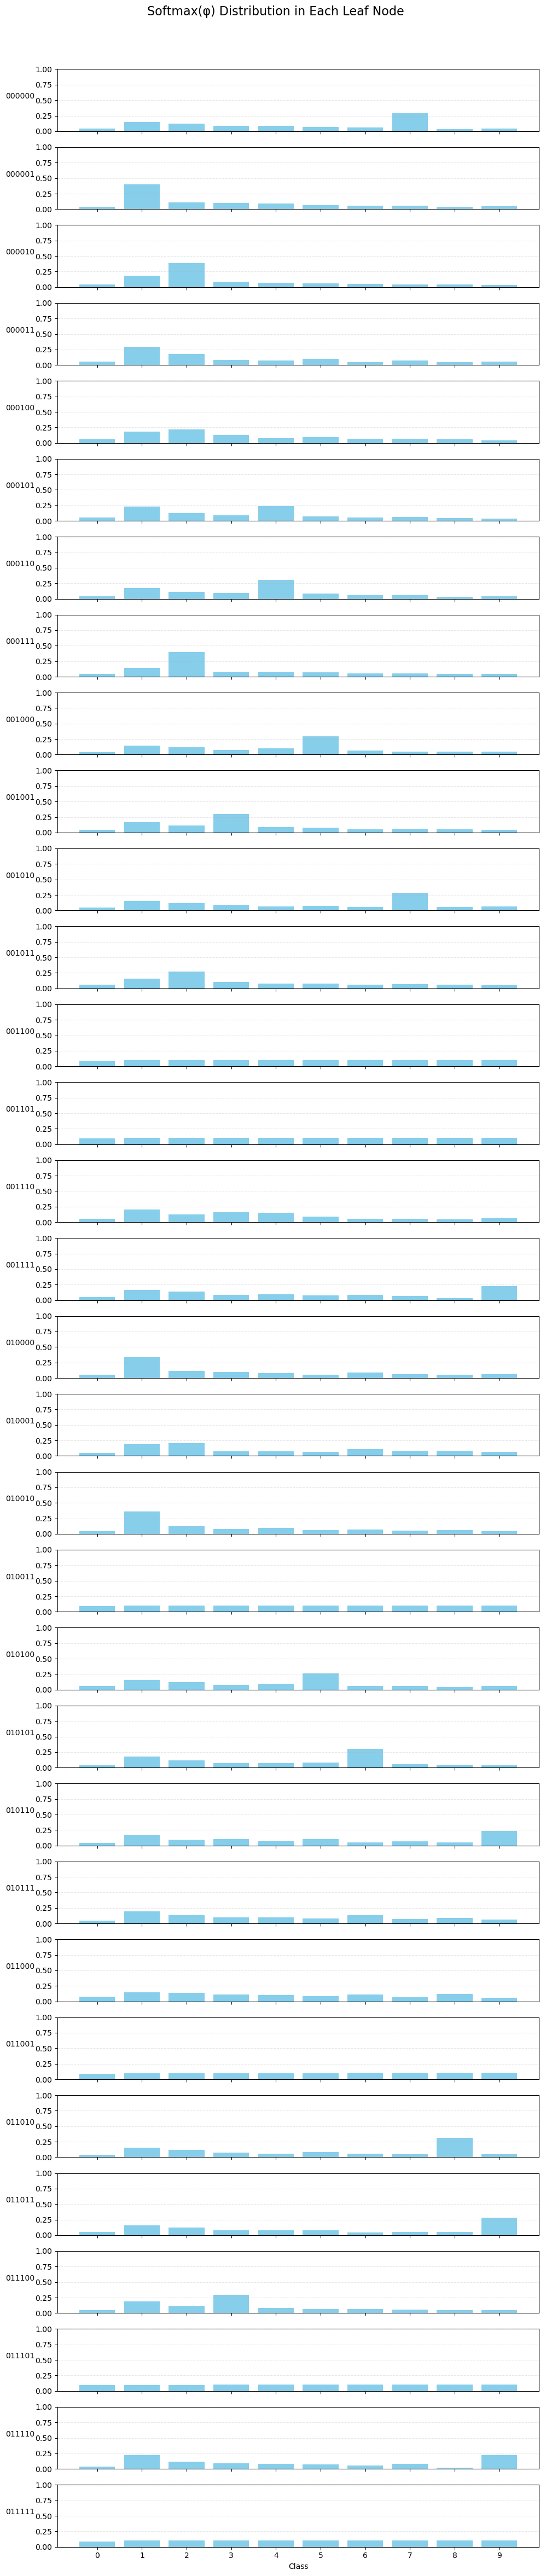

In [34]:
import matplotlib.pyplot as plt
import numpy as np

def plot_leaf_phi_distribution(tree, sess):
    leaves = [n for n in tree.nodes if n.isLeaf]
    n_classes = sess.run(leaves[0].phi).shape[1]

    n_leaves = len(leaves)
    fig, axes = plt.subplots(n_leaves, 1, figsize=(10, n_leaves * 1.5), sharex=True)

    for i, leaf in enumerate(leaves):
        raw_phi = sess.run(leaf.phi)[0]
        soft_phi = np.exp(raw_phi) / (np.sum(np.exp(raw_phi)) + 1e-8)

        ax = axes[i] if n_leaves > 1 else axes
        ax.bar(range(n_classes), soft_phi, color='skyblue')
        ax.set_ylabel(f'{leaf.id}', rotation=0, labelpad=20)
        ax.set_ylim(0, 1)
        ax.grid(axis='y', linestyle='--', alpha=0.3)

    plt.xticks(range(n_classes))
    plt.xlabel("Class")
    plt.suptitle("Softmax(φ) Distribution in Each Leaf Node", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

plot_leaf_phi_distribution(svhn_tree, sess)